# Linear Regression Example

Linear regression implementation with JAX library.

This example is using a low-level approach to better understand all
mechanics behind the training process: the gradients are computed with
`jax.grad`, and the weights are updated with an Optax optimizer.

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import optax

In [2]:
# Parameters.
learning_rate = 0.01
training_steps = 1000
display_step = 50

In [3]:
# Training Data.
X = np.array([3.3, 4.4, 5.5, 6.71, 6.93, 4.168, 9.779, 6.182, 7.59, 2.167,
              7.042, 10.791, 5.313, 7.997, 5.654, 9.27, 3.1])
Y = np.array([1.7, 2.76, 2.09, 3.19, 1.694, 1.573, 3.366, 2.596, 2.53, 1.221,
              2.827, 3.465, 1.65, 2.904, 2.42, 2.94, 1.3])

In [4]:
# Weight and Bias, initialized randomly.
# Random values are generated from a random 'key', which is split to get a
# new key for every use.
key_W, key_b = jax.random.split(jax.random.key(0))
params = {
    'W': jax.random.normal(key_W),
    'b': jax.random.normal(key_b),
}

# Linear regression (Wx + b).
def linear_regression(params, x):
    return params['W'] * x + params['b']

# Mean square error.
def mean_square(y_pred, y_true):
    return jnp.mean(jnp.square(y_pred - y_true))

# Stochastic Gradient Descent Optimizer.
optimizer = optax.sgd(learning_rate)
# The optimizer state is stored outside of the optimizer.
opt_state = optimizer.init(params)

In [5]:
# Optimization process.
# @jax.jit compiles the function with XLA, so it runs much faster
# (see '1_Introduction/transformations.py').
@jax.jit
def run_optimization(params, opt_state):
    # Define the loss as a function of the parameters, to differentiate it.
    def loss_fn(params):
        pred = linear_regression(params, X)
        return mean_square(pred, Y)

    # Compute gradients: 'jax.grad(loss_fn)' is a new function returning the
    # gradient of the loss with respect to 'W' and 'b'.
    gradients = jax.grad(loss_fn)(params)

    # Update W and b following gradients.
    updates, opt_state = optimizer.update(gradients, opt_state)
    params = optax.apply_updates(params, updates)

    # JAX arrays can't be modified in place: return the updated values.
    return params, opt_state

In [6]:
# Run training for the given number of steps.
for step in range(1, training_steps + 1):
    # Run the optimization to update W and b values.
    params, opt_state = run_optimization(params, opt_state)

    if step % display_step == 0:
        pred = linear_regression(params, X)
        loss = mean_square(pred, Y)
        print("step: %i, loss: %f, W: %f, b: %f" % (step, loss, params['W'], params['b']))

step: 50, loss: 1.199666, W: 0.661604, b: -2.107693
step: 100, loss: 0.974005, W: 0.614689, b: -1.775085
step: 150, loss: 0.797037, W: 0.573142, b: -1.480540
step: 200, loss: 0.658254, W: 0.536350, b: -1.219702
step: 250, loss: 0.549417, W: 0.503769, b: -0.988712
step: 300, loss: 0.464065, W: 0.474915, b: -0.784157
step: 350, loss: 0.397130, W: 0.449364, b: -0.603009
step: 400, loss: 0.344637, W: 0.426737, b: -0.442592
step: 450, loss: 0.303472, W: 0.406699, b: -0.300532
step: 500, loss: 0.271188, W: 0.388954, b: -0.174728
step: 550, loss: 0.245871, W: 0.373240, b: -0.063322
step: 600, loss: 0.226017, W: 0.359324, b: 0.035336
step: 650, loss: 0.210447, W: 0.347000, b: 0.122704
step: 700, loss: 0.198236, W: 0.336087, b: 0.200074
step: 750, loss: 0.188660, W: 0.326423, b: 0.268590
step: 800, loss: 0.181151, W: 0.317864, b: 0.329265
step: 850, loss: 0.175262, W: 0.310285, b: 0.382997
step: 900, loss: 0.170643, W: 0.303574, b: 0.430580
step: 950, loss: 0.167021, W: 0.297630, b: 0.472718
st

In [7]:
# Visualize the result.
import matplotlib.pyplot as plt

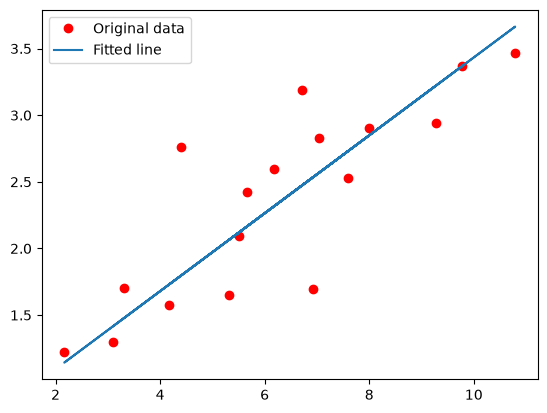

In [8]:
# Graphic display.
plt.plot(X, Y, 'ro', label='Original data')
plt.plot(X, np.array(params['W'] * X + params['b']), label='Fitted line')
plt.legend()
plt.show()